<a href="https://colab.research.google.com/github/MrTu286/TH-AI-Tuan3/blob/main/Buoi_2_TH_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Kích thước dữ liệu: (442, 11)


,count,mean,std,min,25%,50%,75%,max
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
target,442.0,1.521335e+02,77.093005,25.000000,87.000000,140.500000,211.500000,346.000000


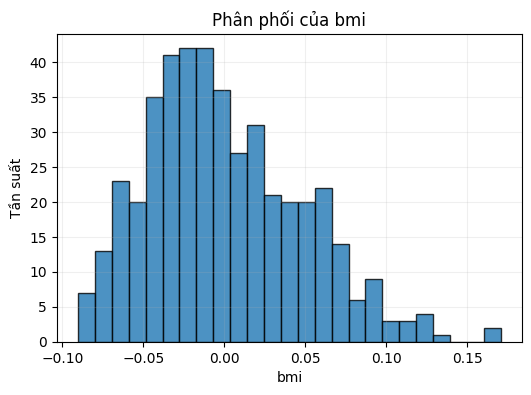

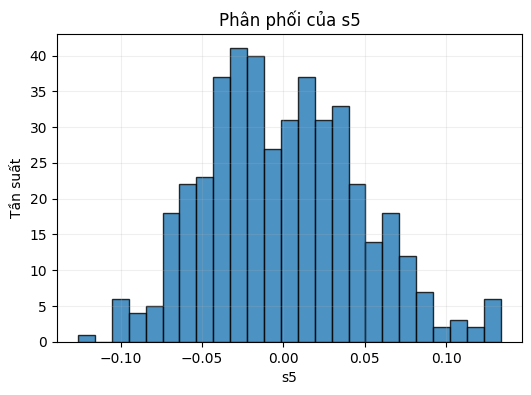

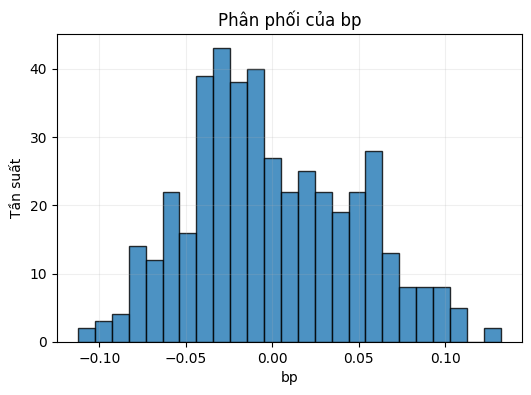

,Biến,Số ngoại lệ theo IQR,Ngưỡng dưới,Ngưỡng trên
0,bmi,3,-0.132445,0.129464
1,s5,4,-0.131762,0.130949
2,bp,0,-0.145106,0.144094


Tương quan với target:


,corr_with_target
bmi,0.586450
s5,0.565883
bp,0.441482


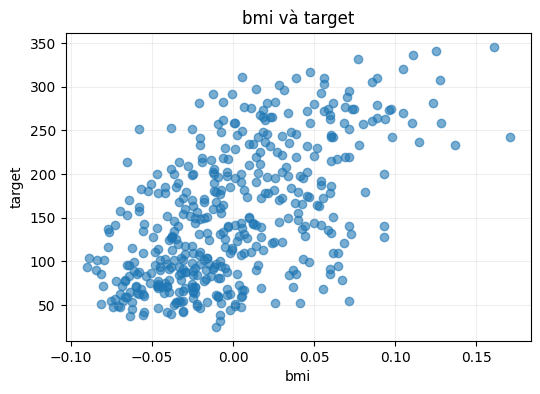

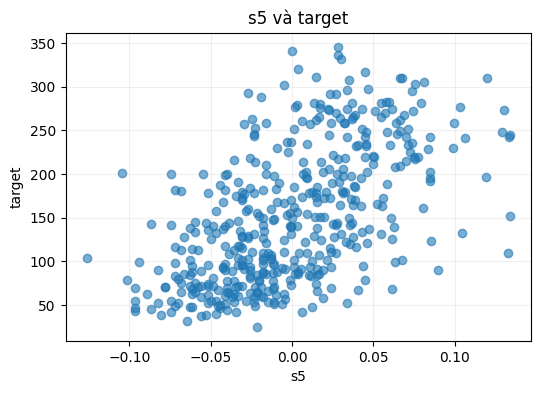

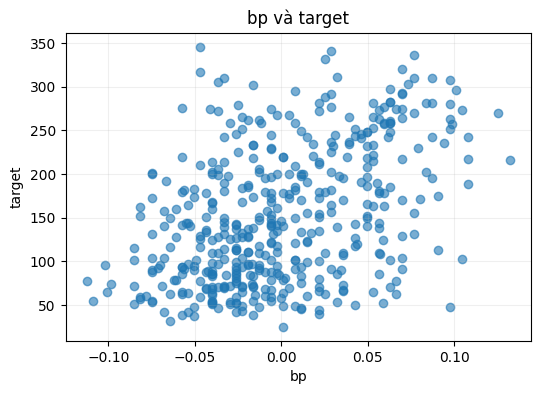

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes

# 1. Tải dữ liệu và đưa vào DataFrame theo đúng mẫu
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()

df = X.copy()
df["target"] = y

# Chọn 3 feature để phân tích cho Bài 1
selected_features = ["bmi", "s5", "bp"]

print("Kích thước dữ liệu:", df.shape)
display(df[selected_features + ["target"]].describe().T)

for col in selected_features:
    plt.figure(figsize=(6, 4))
    plt.hist(df[col], bins=25, edgecolor="black", alpha=0.8)
    plt.title(f"Phân phối của {col}")
    plt.xlabel(col)
    plt.ylabel("Tần suất")
    plt.grid(alpha=0.2)
    plt.show()

    outlier_summary = []

for col in selected_features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary.append([col, n_outliers, lower, upper])

outlier_df = pd.DataFrame(
    outlier_summary,
    columns=["Biến", "Số ngoại lệ theo IQR", "Ngưỡng dưới", "Ngưỡng trên"]
)

display(outlier_df)

# 1. Tính hệ số tương quan với target
corr = df[selected_features + ["target"]].corr(numeric_only=True)
target_corr = corr["target"].drop("target").sort_values(key=np.abs, ascending=False)

print("Tương quan với target:")
display(target_corr.to_frame("corr_with_target"))

# 2. Vẽ Scatter plot giữa từng feature và target
for col in selected_features:
    plt.figure(figsize=(6, 4))
    plt.scatter(df[col], df["target"], alpha=0.6)
    plt.xlabel(col)
    plt.ylabel("target")
    plt.title(f"{col} và target")
    plt.grid(alpha=0.2)
    plt.show()


5 feature có |correlation| cao nhất với target:
['bmi', 's5', 'bp', 's4', 's3']


,Model,MAE,RMSE,R2
0,bmi,52.259976,63.732456,0.233350
1,bmi + bp,50.044115,61.159685,0.293998
2,Top 5 features,43.928286,54.189333,0.445753
3,Toàn bộ 10 features,42.794095,53.853446,0.452603


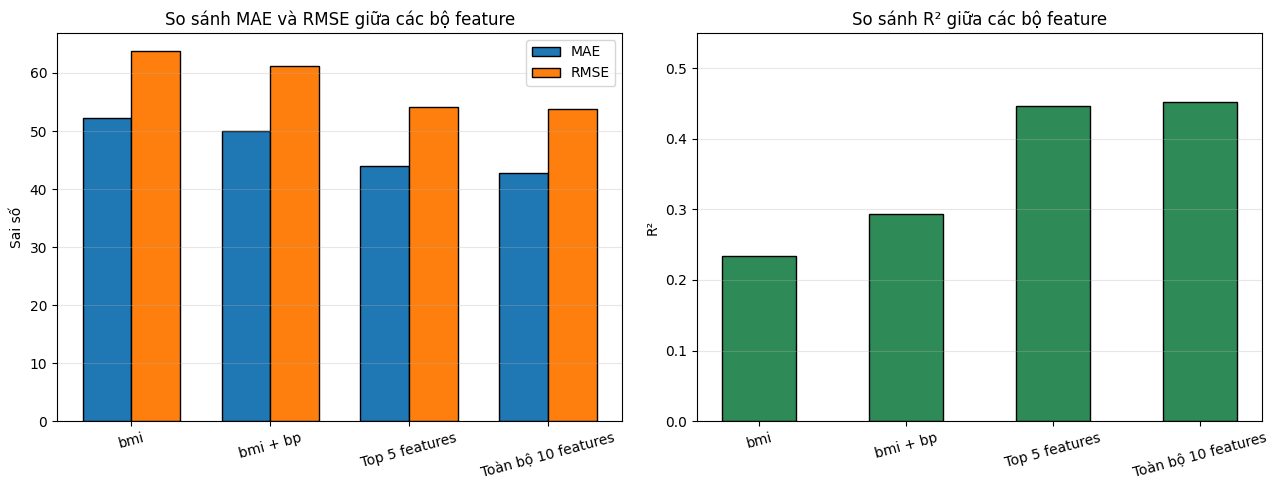

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Chọn 5 feature có |correlation| cao nhất với target theo đúng code mẫu
abs_corr = df.corr(numeric_only=True)["target"].drop("target").abs()
top_features = abs_corr.sort_values(ascending=False).head(5).index.tolist()

print("5 feature có |correlation| cao nhất với target:")
print(top_features)

# Khai báo 4 bộ feature theo yêu cầu đề bài
feature_sets = {
    "bmi": ["bmi"],
    "bmi + bp": ["bmi", "bp"],
    "Top 5 features": top_features,
    "Toàn bộ 10 features": X.columns.tolist()
}

results = []

for model_name, cols in feature_sets.items():
    # Tách dữ liệu train/test cho từng bộ feature
    X_sub = df[cols]
    X_train, X_test, y_train, y_test = train_test_split(
        X_sub,
        y,
        test_size=0.2,
        random_state=42
    )

    # Khai báo, huấn luyện và dự đoán
    model = LinearRegression()
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    # Tính các chỉ số đánh giá
    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Tạo bảng so sánh các mô hình
comparison = pd.DataFrame(results)
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = np.arange(len(comparison["Model"]))
width = 0.35

# Biểu đồ 1: MAE và RMSE
axes[0].bar(x - width/2, comparison["MAE"], width, label="MAE", edgecolor="black")
axes[0].bar(x + width/2, comparison["RMSE"], width, label="RMSE", edgecolor="black")
axes[0].set_title("So sánh MAE và RMSE giữa các bộ feature")
axes[0].set_xticks(x)
axes[0].set_xticklabels(comparison["Model"], rotation=15)
axes[0].set_ylabel("Sai số")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Biểu đồ 2: R² Score
axes[1].bar(x, comparison["R2"], width=0.5, color="seagreen", edgecolor="black")
axes[1].set_title("So sánh R² giữa các bộ feature")
axes[1].set_xticks(x)
axes[1].set_xticklabels(comparison["Model"], rotation=15)
axes[1].set_ylabel("R²")
axes[1].set_ylim(0, 0.55)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Bảng so sánh các mô hình (Tham số mặc định):


,Model,Test MAE,Test RMSE,Test R2,Train R2
0,Linear Regression,42.794095,53.853446,0.452603,0.527919
1,Ridge Regression,46.138858,55.474462,0.419153,0.442403
2,Decision Tree Regression,54.528090,70.546423,0.060654,1.000000
3,Support Vector Regression,56.023724,65.827699,0.182114,0.166804
4,Gradient Boosting Regression,44.603297,53.837131,0.452934,0.835903


Bảng so sánh các mô hình (Sau khi tinh chỉnh tham số):


,Model,Test MAE,Test RMSE,Test R2,Train R2
0,Linear Regression,42.794095,53.853446,0.452603,0.527919
1,Ridge Regression (alpha=0.1),42.996932,53.446112,0.460852,0.520607
2,Decision Tree (max_depth=3),48.096592,59.604541,0.329445,0.516977
3,"Support Vector (C=100, rbf)",39.385398,51.018346,0.508721,0.668081
4,Gradient Boosting (max_depth=2),42.415002,52.105576,0.487559,0.654686


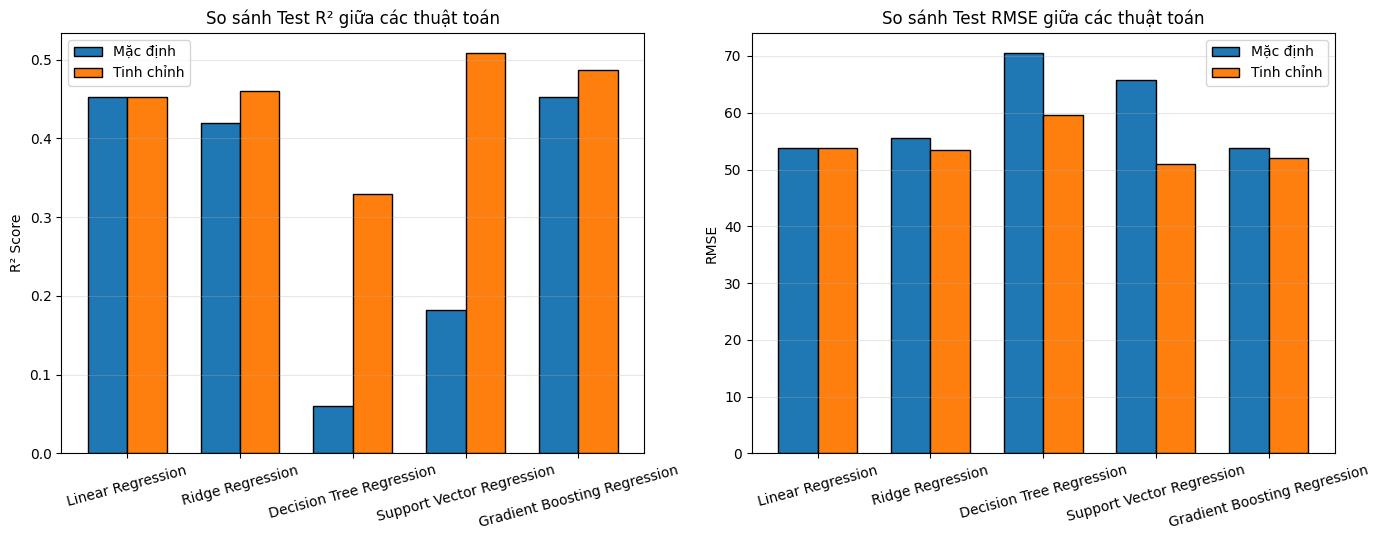

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Chuẩn bị dữ liệu và chia tập train/test (giống phần 2.3 trong tài liệu)
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Khai báo 5 thuật toán với tham số mặc định
models_default = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(random_state=42),
    "Decision Tree Regression": DecisionTreeRegressor(random_state=42),
    "Support Vector Regression": SVR(),
    "Gradient Boosting Regression": GradientBoostingRegressor(random_state=42)
}

results_default = []
for name, model in models_default.items():
    model.fit(X_train, y_train)
    pred_test = model.predict(X_test)
    pred_train = model.predict(X_train)

    mae = mean_absolute_error(y_test, pred_test)
    rmse = np.sqrt(mean_squared_error(y_test, pred_test))
    r2_test = r2_score(y_test, pred_test)
    r2_train = r2_score(y_train, pred_train)

    results_default.append({
        "Model": name,
        "Test MAE": mae,
        "Test RMSE": rmse,
        "Test R2": r2_test,
        "Train R2": r2_train
    })

comparison_default = pd.DataFrame(results_default)
print("Bảng so sánh các mô hình (Tham số mặc định):")
display(comparison_default)
# Tinh chỉnh tham số cho các thuật toán để giảm Overfitting / Underfitting
models_tuned = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression (alpha=0.1)": Ridge(alpha=0.1, random_state=42),
    "Decision Tree (max_depth=3)": DecisionTreeRegressor(max_depth=3, random_state=42),
    "Support Vector (C=100, rbf)": SVR(C=100, kernel="rbf"),
    "Gradient Boosting (max_depth=2)": GradientBoostingRegressor(n_estimators=50, max_depth=2, random_state=42)
}

results_tuned = []
for name, model in models_tuned.items():
    model.fit(X_train, y_train)
    pred_test = model.predict(X_test)
    pred_train = model.predict(X_train)

    results_tuned.append({
        "Model": name,
        "Test MAE": mean_absolute_error(y_test, pred_test),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred_test)),
        "Test R2": r2_score(y_test, pred_test),
        "Train R2": r2_score(y_train, pred_train)
    })

comparison_tuned = pd.DataFrame(results_tuned)
print("Bảng so sánh các mô hình (Sau khi tinh chỉnh tham số):")
display(comparison_tuned)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
x = np.arange(len(comparison_default["Model"]))
width = 0.35

# Biểu đồ 1: So sánh Test R²
axes[0].bar(x - width/2, comparison_default["Test R2"], width, label="Mặc định", edgecolor="black")
axes[0].bar(x + width/2, comparison_tuned["Test R2"], width, label="Tinh chỉnh", edgecolor="black")
axes[0].set_title("So sánh Test R² giữa các thuật toán")
axes[0].set_xticks(x)
axes[0].set_xticklabels(comparison_default["Model"], rotation=15)
axes[0].set_ylabel("R² Score")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Biểu đồ 2: So sánh Test RMSE
axes[1].bar(x - width/2, comparison_default["Test RMSE"], width, label="Mặc định", edgecolor="black")
axes[1].bar(x + width/2, comparison_tuned["Test RMSE"], width, label="Tinh chỉnh", edgecolor="black")
axes[1].set_title("So sánh Test RMSE giữa các thuật toán")
axes[1].set_xticks(x)
axes[1].set_xticklabels(comparison_default["Model"], rotation=15)
axes[1].set_ylabel("RMSE")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Mounted at /content/drive

--- 1. ĐỌC DỮ LIỆU ---
Kích thước dữ liệu sau khi làm sạch: (21613, 19)

--- 2. PHÁT HIỆN NGOẠI LỆ (Quy tắc IQR) ---


,Biến,Số ngoại lệ theo IQR,Ngưỡng dưới,Ngưỡng trên
4,sqft_lot,2425,-3432.0,19160.0
18,sqft_lot15,2194,-2374.5,17557.5
7,view,2124,0.0,0.0
9,grade,1911,5.5,9.5
0,price,1146,-162625.0,1129575.0



--- 3. BASELINE MODEL (18 đặc trưng gốc) ---
MAE  = 127,493.34
RMSE = 212,539.52
R²   = 0.7012

--- 5. SO SÁNH CÁC BỘ ĐẶC TRƯNG (Dùng Linear Regression) ---


,Trường hợp,Số biến,MAE,RMSE,R2
0,Feature Selection (Top 5 gốc),5,164502.842406,261392.192191,0.548040
1,Feature Selection (Top 10 gốc),10,137541.110073,226405.418607,0.660930
2,Baseline (18 features gốc),18,127493.342087,212539.516638,0.701190
3,FE + Selection (Top 15 sau FE),15,129230.397531,222666.097051,0.672038
4,Feature Engineering (25 features),25,121519.248598,209331.404491,0.710143



--- 6. SO SÁNH HIỆU NĂNG CÁC THUẬT TOÁN ---


,Model,Test MAE,Test RMSE,Test R2,Train R2
0,Linear Regression,121519.248598,209331.404491,0.710143,0.749197
1,Ridge Regression,121689.915224,209812.843070,0.708808,0.748490
2,Decision Tree,91568.655248,206508.651106,0.717907,0.918680
3,Support Vector (SVR),96258.670104,222598.203660,0.672238,0.731534
4,Random Forest,73026.344102,158083.227422,0.834695,0.974335
5,Gradient Boosting,81123.911391,154651.644874,0.841794,0.902732



--- 7. TRỰC QUAN HÓA PHẦN DƯ (Gradient Boosting) ---


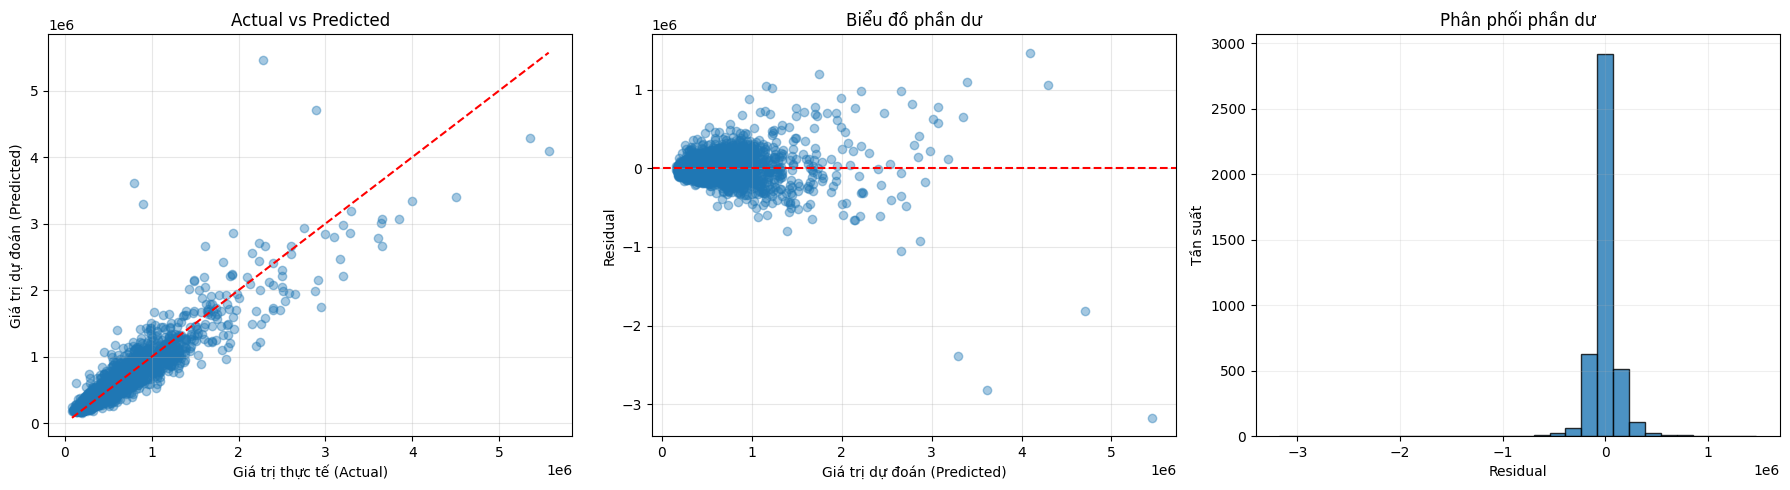

Mean residual (Trung bình phần dư): 5.66


In [4]:
from google.colab import drive
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ==========================================
# 0. KẾT NỐI GOOGLE DRIVE
# ==========================================
drive.mount('/content/drive')
pd.set_option("display.max_columns", None)

# ==========================================
# 1. ĐỌC DỮ LIỆU & DATA CLEANING
# ==========================================
print("\n--- 1. ĐỌC DỮ LIỆU ---")
# Đường dẫn trực tiếp đến file trong thư mục Python trên Drive của bạn
df_raw = pd.read_csv('/content/drive/MyDrive/Python/kc_house_data.csv')

# Loại bỏ cột 'id' và 'date'
df = df_raw.drop(columns=["id", "date"]).copy()
print("Kích thước dữ liệu sau khi làm sạch:", df.shape)

# ==========================================
# 2. EDA & PHÁT HIỆN NGOẠI LỆ
# ==========================================
print("\n--- 2. PHÁT HIỆN NGOẠI LỆ (Quy tắc IQR) ---")
outlier_summary = []
for col in df.columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr  # Đã sửa lỗi thiếu dấu *
    upper = q3 + 1.5 * iqr  # Đã sửa lỗi thiếu dấu *
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary.append([col, n_outliers, lower, upper])

outlier_df = pd.DataFrame(
    outlier_summary,
    columns=["Biến", "Số ngoại lệ theo IQR", "Ngưỡng dưới", "Ngưỡng trên"]
).sort_values(by="Số ngoại lệ theo IQR", ascending=False)
display(outlier_df.head(5))

# ==========================================
# 3. BASELINE MODEL
# ==========================================
X = df.drop(columns=["price"])
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

baseline_model = LinearRegression()
baseline_model.fit(X_train, y_train)
baseline_pred = baseline_model.predict(X_test)

print("\n--- 3. BASELINE MODEL (18 đặc trưng gốc) ---")
print(f"MAE  = {mean_absolute_error(y_test, baseline_pred):,.2f}")
print(f"RMSE = {np.sqrt(mean_squared_error(y_test, baseline_pred)):,.2f}")
print(f"R²   = {r2_score(y_test, baseline_pred):.4f}")

# ==========================================
# 4. FEATURE ENGINEERING
# ==========================================
df_fe = df.copy()

# Feature phi tuyến
df_fe["grade_squared"] = df_fe["grade"] ** 2
df_fe["view_squared"] = df_fe["view"] ** 2

# Feature tương tác (Đã sửa lỗi thiếu dấu *)
df_fe["sqft_grade"] = df_fe["sqft_living"] * df_fe["grade"]
df_fe["sqft_bath"] = df_fe["sqft_living"] * df_fe["bathrooms"]

# Feature tổng hợp (Đã sửa lỗi thiếu dấu -)
df_fe["total_rooms"] = df_fe["bedrooms"] + df_fe["bathrooms"]
df_fe["house_age"] = 2015 - df_fe["yr_built"]
df_fe["is_renovated"] = (df_fe["yr_renovated"] > 0).astype(int)

# Tách train/test cho bộ dữ liệu đã Feature Engineering
X_fe = df_fe.drop(columns=["price"])
y_fe = df_fe["price"]
X_fe_train, X_fe_test, y_fe_train, y_fe_test = train_test_split(
    X_fe, y_fe, test_size=0.2, random_state=42
)

# ==========================================
# 5. FEATURE SELECTION & SO SÁNH
# ==========================================
abs_corr_orig = df.corr(numeric_only=True)["price"].drop("price").abs()
top5_orig = abs_corr_orig.sort_values(ascending=False).head(5).index.tolist()
top10_orig = abs_corr_orig.sort_values(ascending=False).head(10).index.tolist()

abs_corr_fe = df_fe.corr(numeric_only=True)["price"].drop("price").abs()
top15_fe = abs_corr_fe.sort_values(ascending=False).head(15).index.tolist()

fe_fs_cases = {
    "Feature Selection (Top 5 gốc)": (X_train[top5_orig], X_test[top5_orig]),
    "Feature Selection (Top 10 gốc)": (X_train[top10_orig], X_test[top10_orig]),
    "Baseline (18 features gốc)": (X_train, X_test),
    "FE + Selection (Top 15 sau FE)": (X_fe_train[top15_fe], X_fe_test[top15_fe]),
    "Feature Engineering (25 features)": (X_fe_train, X_fe_test)
}

fe_fs_results = []
for case_name, (xt, xte) in fe_fs_cases.items():
    model = LinearRegression()
    model.fit(xt, y_train)
    pred = model.predict(xte)
    fe_fs_results.append({
        "Trường hợp": case_name,
        "Số biến": xt.shape[1],
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

print("\n--- 5. SO SÁNH CÁC BỘ ĐẶC TRƯNG (Dùng Linear Regression) ---")
display(pd.DataFrame(fe_fs_results))

# ==========================================
# 6. HUẤN LUYỆN VÀ SO SÁNH MÔ HÌNH HỌC MÁY
# ==========================================
ml_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0, random_state=42),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=42),
    "Support Vector (SVR)": make_pipeline(StandardScaler(), SVR(C=100000, kernel="rbf")),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

ml_results = []
best_pred = None

for name, model in ml_models.items():
    model.fit(X_fe_train, y_fe_train)
    pred_test = model.predict(X_fe_test)
    pred_train = model.predict(X_fe_train)

    if name == "Gradient Boosting":
        best_pred = pred_test

    ml_results.append({
        "Model": name,
        "Test MAE": mean_absolute_error(y_fe_test, pred_test),
        "Test RMSE": np.sqrt(mean_squared_error(y_fe_test, pred_test)),
        "Test R2": r2_score(y_fe_test, pred_test),
        "Train R2": r2_score(y_fe_train, pred_train)
    })

print("\n--- 6. SO SÁNH HIỆU NĂNG CÁC THUẬT TOÁN ---")
display(pd.DataFrame(ml_results))

# ==========================================
# 7. CHẨN ĐOÁN PHẦN DƯ (Mô hình Gradient Boosting)
# ==========================================
print("\n--- 7. TRỰC QUAN HÓA PHẦN DƯ (Gradient Boosting) ---")
# Đã sửa lỗi khoảng trắng thụt lề ở dòng này
residuals = y_fe_test.values - best_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Actual vs Predicted
min_val = min(y_fe_test.min(), best_pred.min())
max_val = max(y_fe_test.max(), best_pred.max())
axes[0].scatter(y_fe_test, best_pred, alpha=0.4)
axes[0].plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--")
axes[0].set_xlabel("Giá trị thực tế (Actual)")
axes[0].set_ylabel("Giá trị dự đoán (Predicted)")
axes[0].set_title("Actual vs Predicted")
axes[0].grid(alpha=0.3)

# Residual Plot
axes[1].scatter(best_pred, residuals, alpha=0.4)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Giá trị dự đoán (Predicted)")
axes[1].set_ylabel("Residual")
axes[1].set_title("Biểu đồ phần dư")
axes[1].grid(alpha=0.3)

# Phân phối phần dư
axes[2].hist(residuals, bins=30, edgecolor="black", alpha=0.8)
axes[2].set_xlabel("Residual")
axes[2].set_ylabel("Tần suất")
axes[2].set_title("Phân phối phần dư")
axes[2].grid(alpha=0.2)

plt.tight_layout()
plt.show()

print(f"Mean residual (Trung bình phần dư): {np.mean(residuals):,.2f}")